In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from tensorflow.keras import models
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from tensorflow.keras import models, layers

data_path = '../Data/combined_data_by_year/'

dam = pd.read_parquet(f'{data_path}dam_data_2023_2026.parquet')
rtm = pd.read_parquet(f'{data_path}rtm_data_2023_2026.parquet')
load = pd.read_parquet(f'{data_path}load_data_2023_2026.parquet')
outage = pd.read_parquet(f'{data_path}outage_data_2023_2026.parquet')
solar = pd.read_parquet(f'{data_path}solar_data_2023_2026.parquet')
wind = pd.read_parquet(f'{data_path}wind_data_2023_2026.parquet')

data = pd.merge(dam, rtm, on='interval_end_utc', suffixes=('_dam', '_rtm'))
data = pd.merge(data, load, on='interval_end_utc', suffixes=('', '_load'))
data = pd.merge(data, outage, on='interval_end_utc', suffixes=('', '_outage'))
data = pd.merge(data, solar, on='interval_end_utc', suffixes=('', '_solar'))
data = pd.merge(data, wind, on='interval_end_utc', suffixes=('', '_wind'))

data = data.sort_values('interval_end_utc').reset_index(drop=True)

data.loc[data['lmp_dam'] > 132, 'lmp_dam'] = 132
data.loc[data['lmp_rtm'] > 132, 'lmp_rtm'] = 132

load_forecast = data['load_forecast'].astype(float).values.reshape(-1, 1) 
miso_solar = data['miso'].astype(float).values.reshape(-1, 1)
miso_wind = data['miso_wind'].astype(float).values.reshape(-1, 1)
lmp_dam = data['lmp_dam'].astype(float).values.reshape(-1, 1)
lmp_rtm = data['lmp_rtm'].astype(float).values.reshape(-1, 1) #target/label



c:\Users\atoll\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
window_size = 288

features = np.concatenate((
    lmp_dam,
    load_forecast,
    miso_solar,
    miso_wind
), axis=1)

X = []
y = []
target_dates = []

for i in range(window_size, len(data)):
    X.append(features[i - window_size:i, :])
    y.append(lmp_rtm[i, 0])
    target_dates.append(
        data['interval_end_utc'].iloc[i]
    )

X = np.array(X)
y = np.array(y)

X_train, X_test, y_train, y_test, dates_train, dates_test = train_test_split(
    X, y, target_dates, test_size=0.2, shuffle=False
)





In [3]:

scaler_x = MinMaxScaler(feature_range=(0, 1))

scaler_x.fit(X_train.reshape(-1, X_train.shape[2]))

scaled_x_training = scaler_x.transform(
    X_train.reshape(-1, X_train.shape[2])
)

scaled_x_testing = scaler_x.transform(
    X_test.reshape(-1, X_test.shape[2])
)

X_train = scaled_x_training.reshape(
    X_train.shape[0],
    X_train.shape[1],
    X_train.shape[2]
)

X_test = scaled_x_testing.reshape(
    X_test.shape[0],
    X_test.shape[1],
    X_test.shape[2]
)

scaler_y = MinMaxScaler(feature_range=(0, 1))

y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

y_train = scaler_y.fit_transform(y_train)

y_test = scaler_y.transform(y_test)

In [4]:
def build_model(units=64, dropout=0.1, learning_rate=0.0001):

    model = models.Sequential([
        layers.Input((window_size, 4)),
        layers.LSTM(units=units, return_sequences=True),
        layers.Dropout(0.1),
        layers.LSTM(units),
        layers.Dense(1)
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.0001),
        loss="mse"
    )

    return model


early_stopping = EarlyStopping(
    mode="min", patience=3, min_delta=1e-3,
    restore_best_weights=True
)
lstm = KerasRegressor(
    model=build_model,
    batch_size=64,
    verbose=1,
    epochs=20,
    validation_split=0.1,
    callbacks=[early_stopping]
)



In [6]:
param_grid = {
    'model__units': [32]
}

tscv = TimeSeriesSplit(n_splits=2)

grid = GridSearchCV(
    estimator=lstm,
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_squared_error',
    verbose=3,
    n_jobs=1
)

grid.fit(X_train, y_train)

grid.cv_results_

Fitting 2 folds for each of 1 candidates, totalling 2 fits
Epoch 1/20
6214/6214 ━━━━━━━━━━━━━━━━━━━━ 437s 70ms/step - loss: 0.0039 - val_loss: 0.0060
Epoch 2/20
6214/6214 ━━━━━━━━━━━━━━━━━━━━ 420s 68ms/step - loss: 0.0026 - val_loss: 0.0064
Epoch 3/20
6214/6214 ━━━━━━━━━━━━━━━━━━━━ 419s 67ms/step - loss: 0.0025 - val_loss: 0.0057
Epoch 4/20
6214/6214 ━━━━━━━━━━━━━━━━━━━━ 421s 68ms/step - loss: 0.0029 - val_loss: 0.0068
6905/6905 ━━━━━━━━━━━━━━━━━━━━ 158s 23ms/step
[CV 1/2] END ..................model__units=32;, score=-0.006 total time=31.4min
Epoch 1/20
12428/12428 ━━━━━━━━━━━━━━━━━━━━ 899s 72ms/step - loss: 0.0040 - val_loss: 0.0163
Epoch 2/20
12428/12428 ━━━━━━━━━━━━━━━━━━━━ 881s 71ms/step - loss: 0.0033 - val_loss: 0.0121
Epoch 3/20
12428/12428 ━━━━━━━━━━━━━━━━━━━━ 869s 70ms/step - loss: 0.0031 - val_loss: 0.0150
Epoch 4/20
12428/12428 ━━━━━━━━━━━━━━━━━━━━ 876s 71ms/step - loss: 0.0030 - val_loss: 0.0124
Epoch 5/20
12428/12428 ━━━━━━━━━━━━━━━━━━━━ 864s 70ms/step - loss: 0.0030 - va

{'mean_fit_time': array([3076.94403362]),
 'std_fit_time': array([1354.84886336]),
 'mean_score_time': array([163.49617147]),
 'std_score_time': array([1.14690042]),
 'param_model__units': masked_array(data=[32],
              mask=[False],
        fill_value=999999),
 'params': [{'model__units': 32}],
 'split0_test_score': array([-0.00578436]),
 'split1_test_score': array([-0.00998723]),
 'mean_test_score': array([-0.00788579]),
 'std_test_score': array([0.00210143]),
 'rank_test_score': array([1], dtype=int32)}

In [11]:
from sklearn.metrics import r2_score, mean_squared_error

In [12]:
# Get predictions
y_pred = grid.best_estimator_.predict(X_test)

# Inverse transform predictions
y_pred_original = scaler_y.inverse_transform(
    y_pred.reshape(-1, 1)
)

# Inverse transform actual values
y_test_original = scaler_y.inverse_transform(
    y_test.reshape(-1, 1)
)

# Calculate RMSE in original units
rmse = np.sqrt(mean_squared_error(y_test_original, y_pred_original))

print("Test RMSE:", rmse)

5179/5179 ━━━━━━━━━━━━━━━━━━━━ 163s 31ms/step
Test RMSE: 12.939550936782206


In [13]:
r2 = r2_score(y_test_original, y_pred_original)

print("Test R²:", r2)

Test R²: 0.4266588937118463


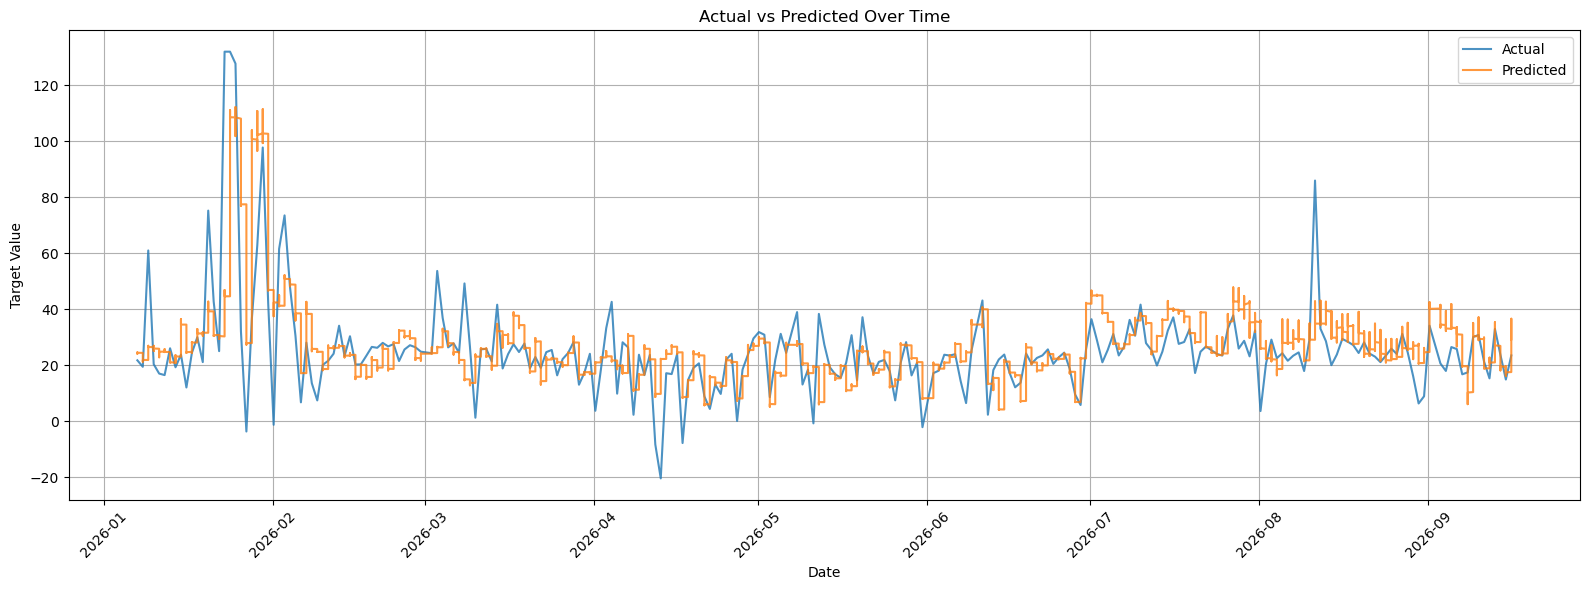

In [15]:
# Convert dates to datetime
dates_test = pd.to_datetime(dates_test)

# Plot
plt.figure(figsize=(16, 6))

plt.plot(dates_test, y_test_original, label='Actual', alpha=0.8)
plt.plot(dates_test, y_pred_original, label='Predicted', alpha=0.8)

plt.title('Actual vs Predicted Over Time')
plt.xlabel('Date')
plt.ylabel('Target Value')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()